# The squad data — what was assembled, and what it will and won't support

Notebook 01 established the strength model: Jordan climbed about 0.7 goals of
expected goal difference between 2015 and 2026, the climb came from attack
rather than defence, and no regional peer matched it.

Answering *where the extra goals came from* needs a different kind of data —
who was on the pitch, and who scored. This notebook shows what that data is,
how much of it exists, and where it stops. **No analysis here**; the point is
that every later claim can be traced to a row someone can check.

```
cd JordanData
python fbref_fetch.py      # scrape (slow, resumable, cached)
python fbref_parse.py      # HTML -> tidy tables
python wiki_arabcup.py     # the 10 matches FBref does not carry
python merge_sources.py    # combine, with provenance
python match_table.py      # flatten to match and goal grain
```

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))

import viz
viz.use_style()

SQUAD = ROOT / "outputs" / "squad"
mt = pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"])
goals = pd.read_csv(SQUAD / "goals.csv", parse_dates=["date"])
apps = pd.read_csv(SQUAD / "appearances_combined.csv")

print(f"match_table   {len(mt):>5} matches   {mt.date.min():%Y-%m} to {mt.date.max():%Y-%m}")
print(f"goals         {len(goals):>5} Jordan goals")
print(f"appearances   {len(apps):>5} player-matches")
print(f"\nmatches with a full starting XI: {int(mt.has_xi.sum())} of {len(mt)}")

match_table     174 matches   2011-07 to 2026-06
goals           261 Jordan goals
appearances    4893 player-matches

matches with a full starting XI: 166 of 174


## 1. Where it came from

Two sources, and every row says which. FBref supplies the bulk; Wikipedia
supplies the ten Arab Cup matches FBref does not carry at all — including the
entire December 2025 tournament, where Jordan won five of six and reached the
final. Leaving those out would have biased the squad measures in the worst
direction, since Arab Cup is exactly the kind of fixture where a second-string
XI appears.

In [2]:
print("matches by source")
print(mt.source.value_counts().rename("n").to_string())
print("\ngoals by source")
print(goals.source.value_counts().rename("n").to_string())
print("\nappearances by source")
print(apps.source.value_counts().rename("n").to_string())

matches by source
source
fbref        164
wikipedia     10

goals by source
source
fbref                231
wikipedia             19
wikipedia_results     11

appearances by source
source
fbref        4736
wikipedia     157


## 2. Coverage

The authority for *which matches exist* is `data/results.csv`, not FBref — so a
match FBref lacks shows up as a gap rather than vanishing. Since 2015 that
gives 156 matches, of which 136 (87%) yield a full starting XI.

findfont: Failed to find font weight semibold, now using 700.


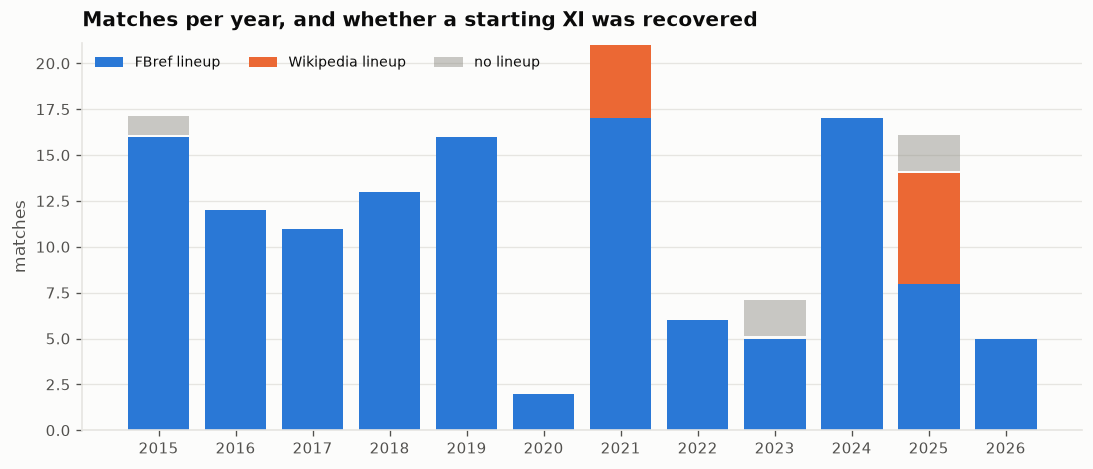

since 2015: 138 of 143 matches with a full XI (97%)


In [3]:
cov = mt[mt.date >= "2015-01-01"].copy()
cov["yr"] = cov.date.dt.year
tab = (cov.assign(fb=cov.source.eq("fbref") & cov.has_xi,
                  wk=cov.source.eq("wikipedia") & cov.has_xi,
                  none=~cov.has_xi)
         .groupby("yr")[["fb", "wk", "none"]].sum())

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(tab.index, tab.fb, color=viz.BLUE, label="FBref lineup", zorder=2)
ax.bar(tab.index, tab.wk, bottom=tab.fb, color=viz.ORANGE,
       label="Wikipedia lineup", zorder=2)
ax.bar(tab.index, tab.none, bottom=tab.fb + tab.wk + 0.12,
       color=viz.INK_MUTED, alpha=0.45, label="no lineup", zorder=2)
viz.despine(ax)
ax.set_title("Matches per year, and whether a starting XI was recovered")
ax.set_ylabel("matches")
ax.set_xticks(tab.index)
ax.legend(loc="upper left", ncols=3, fontsize=8.5)
plt.show()

n = len(cov)
print(f"since 2015: {int(cov.has_xi.sum())} of {n} matches with a full XI "
      f"({cov.has_xi.mean():.0%})")

In [4]:
gaps = cov[~cov.has_xi].groupby("tournament").size().rename("matches")
print("the remaining gaps, by competition:")
print(gaps.sort_values(ascending=False).to_string())

the remaining gaps, by competition:
tournament
Friendly    5


Every remaining gap is a **friendly** whose FBref report carries no lineup, plus
a handful of WAFF and invitational fixtures FBref does not track. There is no
source for them: Wikipedia's results articles carry match metadata and scorers
but no lineups, which was checked directly.

## 3. What each column is, and how complete it is

The table is deliberately wide — 49 columns — because it has to serve both
"what happened in this match" and "who was on the pitch".

In [5]:
groups = {
    "identity": ["match_id", "date", "year", "comp", "round", "tournament",
                 "opponent", "venue", "source"],
    "result": ["gf", "ga", "gd", "result"],
    "model expectation": ["expected_gf", "expected_ga", "expected_gd",
                          "gf_above_expected", "gd_above_expected",
                          "strength_at_match"],
    "the XI": ["n_starters", "has_xi", "starting_xi", "subs_used", "age_mean",
               "age_sd", "n_gk", "n_df", "n_mf", "n_fw"],
    "shape": ["formation", "opp_formation", "formation_best", "formation_source",
              "xi_shape", "band_gk", "band_df", "band_mf", "band_fw"],
    "in-match": ["n_subs_used", "first_sub_minute", "median_sub_minute",
                 "n_cards", "captain", "manager"],
    "context": ["attendance", "attendance_source", "referee", "referee_source",
                "possession"],
}
rows = []
for g, cols in groups.items():
    for c in cols:
        if c in mt.columns:
            rows.append({"group": g, "column": c,
                         "filled": mt[c].notna().sum(),
                         "pct": round(100 * mt[c].notna().mean())})
completeness = pd.DataFrame(rows)
completeness.groupby("group").pct.agg(["min", "max", "size"]).rename(
    columns={"size": "columns"})

,min,max,columns
group,,,
context,16,100,5
identity,94,100,9
in-match,84,96,6
model expectation,100,100,6
result,100,100,4
shape,56,95,9
the XI,94,100,10


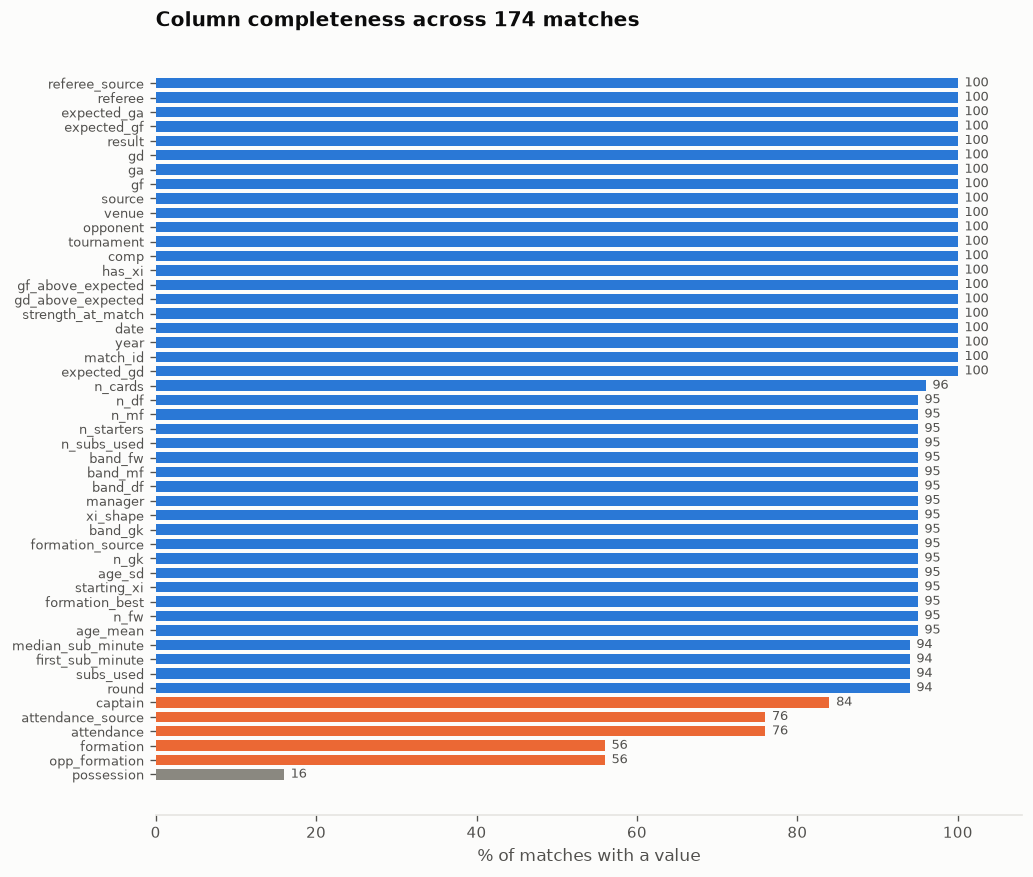

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 7.2))
d = completeness.sort_values("pct").reset_index(drop=True)
# thresholds set where the meaning changes, not on round numbers: at/above 90
# is effectively complete, 50-90 has real holes, below 50 is not usable alone
colour = np.where(d.pct >= 90, viz.BLUE,
                  np.where(d.pct >= 50, viz.ORANGE, viz.INK_MUTED))
ax.barh(np.arange(len(d)), d.pct, color=colour, zorder=2, height=0.72)
ax.set_yticks(np.arange(len(d)), d.column, fontsize=8)
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 108)
ax.set_title("Column completeness across 174 matches")
ax.set_xlabel("% of matches with a value")
for i, r in d.iterrows():
    ax.annotate(f"{r.pct:.0f}", xy=(r.pct, i), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=7.5,
                color=viz.INK_2)
plt.show()

Three columns sit low and each for a different reason, none of them fixable:

| column | why |
|---|---|
| `possession` | 27 of 174. Gated by competition, never recorded for friendlies. Checked against six sources and closed as a dead end. |
| `formation` | 97 of 174 from FBref. `formation_best` raises it to 166 using a shape derived from the positions the source states — a separate column, because it reproduces a known formation only 69% of the time. |
| `attendance` | the Wikipedia articles leave it blank too. |

## 4. One match, end to end

The clearest test of a dataset is whether a single row can be read and checked
against the outside world.

In [7]:
def show(date):
    r = mt[mt.date == date].iloc[0]
    print(f"{r.date:%Y-%m-%d}  Jordan {int(r.gf)}-{int(r.ga)} {r.opponent}"
          f"   [{r.comp}{', ' + str(r['round']) if pd.notna(r['round']) else ''}]")
    print(f"  venue {r.venue} · {r.referee} · attendance "
          f"{int(r.attendance) if pd.notna(r.attendance) else 'n/a'}"
          f" · manager {r.manager}")
    print(f"  formation {r.formation_best} ({r.formation_source})"
          f"   shape {r.xi_shape}   XI age {r.age_mean:.1f}")
    print(f"  model expected {r.expected_gf:.2f}-{r.expected_ga:.2f}"
          f"   -> {r.gf_above_expected:+.2f} goals above expectation")
    print(f"  subs {int(r.n_subs_used)} (first {r.first_sub_minute:.0f}')"
          f"   cards {int(r.n_cards)}")
    print("\n  starting XI")
    for p in json.loads(r.starting_xi):
        print(f"    {str(p['no']):>2}  {p['name']:<24} {p['pos']}  "
              f"{p['min']}'  age {p['age']}")
    gs = goals[goals.match_id == r.match_id]
    if len(gs):
        print("\n  goals")
        for _, g in gs.iterrows():
            extra = f" (assist {g.assist})" if pd.notna(g.assist) else ""
            print(f"    {int(g.minute):>3}'  {g.scorer}{extra}  [{g.type}]")

show("2025-12-18")

2025-12-18  Jordan 2-3 Morocco   [Arab Cup]
  venue neutral · Glenn Nyberg · attendance 84517 · manager Jamal Sellami
  formation 3-4-3 (derived_from_lineup)   shape 3-4-3   XI age 27.6
  model expected 0.47-1.57   -> +1.53 goals above expectation
  subs 6 (first 46')   cards 2

  starting XI
     1  Yazeed Abulaila          GK  119'  age 32.9
     3  Abdallah Nasib           DF  119'  age 31.8
    19  Saed Al-Rosan            DF  119'  age 28.9
    21  Nizar Al Rashdan         MF  119'  age 26.7
    20  Mohannad Abu Taha        MF  119'  age 22.9
     9  Ali Olwan                FW  119'  age 25.7
     4  Husam Abu Dahab          DF  104'  age 25.6
    13  Mahmoud Al-Mardi         FW  90'  age 32.2
     6  Amer Jamous              MF  81'  age 23.5
    17  Issam Smeeri             MF  46'  age 26.6
     7  Mohammad Aburiziq        FW  46'  age 26.9

  goals
     48'  Ali Olwan  [goal]
     68'  Ali Olwan  [penalty_goal]


That match is one of the ten with no FBref record at all — lineup, minutes,
cards, captain and scorers are all recovered from Wikipedia, and the scoreline
agrees with `results.csv`.

## 5. The goals table, and why it is trustworthy

261 goals. The check that matters is whether they reconcile against the
scorelines we already hold, because a goal table that does not add up to the
result is wrong somewhere.

findfont: Failed to find font weight semibold, now using 700.


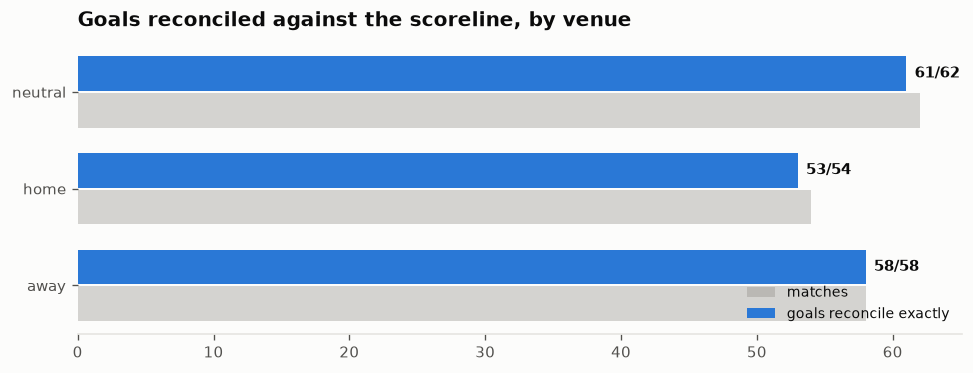

overall: 172/174 matches reconcile (99%)
spine goals 264, goals found 261


In [8]:
cnt = goals.groupby("match_id").size().rename("found")
chk = mt.merge(cnt, on="match_id", how="left")
chk["found"] = chk.found.fillna(0).astype(int)
chk = chk[chk.gf.notna()]
chk["ok"] = chk.found == chk.gf

by_venue = chk.groupby("venue").agg(matches=("ok", "size"), reconcile=("ok", "sum"),
                                    goals=("gf", "sum"), found=("found", "sum"))
fig, ax = plt.subplots(figsize=(8, 3))
y = np.arange(len(by_venue))
ax.barh(y - 0.19, by_venue.matches, height=0.36, color=viz.INK_MUTED,
        alpha=0.35, label="matches", zorder=2)
ax.barh(y + 0.19, by_venue.reconcile, height=0.36, color=viz.BLUE,
        label="goals reconcile exactly", zorder=2)
ax.set_yticks(y, by_venue.index)
viz.despine(ax, keep=("bottom",)); ax.grid(axis="y", visible=False)
ax.set_title("Goals reconciled against the scoreline, by venue")
ax.legend(loc="lower right", fontsize=8.5)
for i, r in enumerate(by_venue.itertuples()):
    ax.annotate(f"{r.reconcile}/{r.matches}", xy=(r.reconcile, i + 0.19),
                xytext=(5, 0), textcoords="offset points", va="center",
                fontsize=9, color=viz.INK, fontweight="semibold")
plt.show()

print(f"overall: {int(chk.ok.sum())}/{len(chk)} matches reconcile ({chk.ok.mean():.0%})")
print(f"spine goals {int(chk.gf.sum())}, goals found {int(chk.found.sum())}")

The **neutral** row is the one worth dwelling on. Jordan plays a third of its
matches on neutral ground — every Asian Cup and World Cup fixture — and FBref's
event feed leaves its `side` field null there. Attributing goals by that field
would have silently dropped every one of them, biasing precisely the period
under study. Goals are instead attributed by checking the scorer against
Jordan's own appearance list for that match.

The six matches that do not reconcile are friendlies whose FBref report contains
no events at all, and whose scorers Wikipedia also leaves blank or contradicts.
Fourteen goals are absent from every source checked — not lost in parsing.

In [9]:
# Keyed on player id, never on name. The same player is written differently by
# different sources -- FBref "Nizar Al Rashdan", Wikipedia "Nizar Al-Rashdan",
# and the Arab Cup articles use bare surnames -- so grouping by name splits one
# player into several rows.
goals["post"] = goals.date >= "2022-07-01"
scored = goals.dropna(subset=["scorer_player_id"])
canonical = scored.groupby("scorer_player_id").scorer.agg(lambda s: s.mode().iat[0])

top = scored.pivot_table(index="scorer_player_id", columns="post",
                         values="match_id", aggfunc="count", fill_value=0)
top.columns = ["pre-2022", "post-2022"]
top["total"] = top.sum(axis=1)
top.index = top.index.map(canonical)
top.index.name = "scorer"
print(f"{len(scored)} of {len(goals)} goals have a scorer "
      f"(the rest are own goals for Jordan)")
top.sort_values("total", ascending=False).head(12)

257 of 261 goals have a scorer (the rest are own goals for Jordan)


,pre-2022,post-2022,total
scorer,,,
Hamza Al-Dardour,29,0,29
Ali Olwan,8,19,27
Musa Al-Taamari,10,14,24
Yazan Al-Naimat,5,15,20
Baha' Faisal,17,0,17
Hassan Abdel-Fattah,13,0,13
Ahmad Hayel,11,0,11
Abdallah Deeb,9,0,9
Mahmoud Al-Mardi,4,5,9


That table is the reason the next notebook exists, and it is deliberately left
un-analysed here. Note only that it is not the same set of names on both sides.

## What this data can and cannot be asked

**Can**: who started, for how long, at what age; how the XI changed between
matches; who scored, when, from which position; how many substitutes and when;
how the result compared with what the model expected.

**Cannot**: anything needing shots, possession or ball location across the 2022
boundary. Shot data begins in 2024, possession exists for 27 matches and never
for friendlies, and ball location does not exist at all. *"Did Jordan create
more chances"* is unanswerable, and no amount of further sourcing changes that.

One caveat that outlives this notebook: FBref does not track Arab Cup, WAFF or
several invitational fixtures, and **all of those are competitive** — often the
rotation-heavy ones. Ten Arab Cup matches are now recovered, but WAFF and the
invitationals are not, so squad turnover measured here is still biased slightly
downward.